In [1]:
# -----------------------------------------------
# Step 0: Importing all required libraries and packages
# -----------------------------------------------

# PyTorch Core Libraries (for model building, training, optimization)
import torch                  # Core PyTorch package (tensor computation)
import torch.nn as nn          # Neural Network module (layers, activations, etc.)
import torch.optim as optim    # Optimizers (SGD, Adam, etc.)
from torch.utils.data import DataLoader   # For batching and loading datasets

# PyTorch Vision Libraries (pre-trained models, datasets, image transforms)
from torchvision import datasets, models, transforms

# -----------------------------------------------
# Utilities for handling files, arrays, images, and plotting
# -----------------------------------------------

import os                     # File and directory operations
import numpy as np             # Numerical operations and array handling
from PIL import Image          # For image loading and preprocessing
import matplotlib.pyplot as plt  # Plotting graphs and images

# -----------------------------------------------
# Progress bars and reproducibility
# -----------------------------------------------

from tqdm import tqdm          # Progress bar for loops
import random                  # For reproducibility (setting seeds if needed)

# -----------------------------------------------
# For plotting loss/accuracy curves
# (Redundant since plt is already imported above, but kept here for emphasis)
import matplotlib.pyplot as plt

# -----------------------------------------------
# Time tracking and model checkpointing utilities
# -----------------------------------------------

import time                    # For measuring training times
import copy                    # For saving the best model state during training

# -----------------------------------------------
# Metrics & visualization (confusion matrix, classification report, seaborn plots)
# -----------------------------------------------

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  # For evaluation metrics
import seaborn as sns          # For beautiful heatmap/plots (Confusion Matrix visualization)

In [2]:
# -----------------------------------------------
# Define image preprocessing and augmentation transforms
# -----------------------------------------------

data_transforms = {

    # Transformations applied to the training data
    'train': transforms.Compose([
        transforms.Resize((224, 224)),             # Resize images to 224x224 (required input size for most CNN models like ResNet)
        transforms.RandomHorizontalFlip(),         # Data augmentation: Randomly flip images horizontally to increase dataset variety
        transforms.ToTensor(),                     # Convert PIL image or numpy array to PyTorch tensor (C x H x W, scaled [0,1])
        transforms.Normalize([0.485, 0.456, 0.406],# Normalize using ImageNet means (for pre-trained models)
                             [0.229, 0.224, 0.225])# Normalize using ImageNet standard deviations
    ]),

    # Transformations applied to the validation data (no augmentation, only resizing and normalization)
    'val': transforms.Compose([
        transforms.Resize((224, 224)),             # Resize images to 224x224 (same as training)
        transforms.ToTensor(),                     # Convert image to tensor
        transforms.Normalize([0.485, 0.456, 0.406],# Normalize using ImageNet means
                             [0.229, 0.224, 0.225])# Normalize using ImageNet standard deviations
    ])
}


In [3]:
# Define the correct path to the Fruits-360 dataset root directory
# Ensure the folder structure matches the expected 'Training' and 'Test' subfolders
import glob
# Find the dataset folder wherever Kaggle mounted it
data_dir = glob.glob('/kaggle/input/**/fruits-360-original-size', recursive=True)[0]
print("Using data from:", data_dir)

# Create training and validation datasets using ImageFolder
# Automatically assigns labels based on subfolder names
# Applies the defined data transformations (augmentation for training, basic preprocessing for validation)
image_datasets = {
    'train': datasets.ImageFolder(root=os.path.join(data_dir, 'Training'), transform=data_transforms['train']),
    'val': datasets.ImageFolder(root=os.path.join(data_dir, 'Test'), transform=data_transforms['val'])
}

# Create dataloaders for training and validation sets
# Uses batch size of 32
# Training loader shuffles the data to improve model generalization
# Validation loader does not shuffle data to maintain consistent evaluation
# num_workers=4 uses all 4 Kaggle CPU cores to load images faster
dataloaders = {
    'train': DataLoader(image_datasets['train'], batch_size=32, shuffle=True, num_workers=4),
    'val': DataLoader(image_datasets['val'], batch_size=32, shuffle=False, num_workers=4)
}

# Retrieve the class names from the training dataset
# This will be used later to interpret predictions
class_names = image_datasets['train'].classes

# Print the total number of classes detected in the dataset
print("Number of classes:", len(class_names))

Using data from: /kaggle/input/datasets/moltean/fruits/fruits-360_original-size/fruits-360-original-size
Number of classes: 163


In [4]:
# Load a pre-trained ResNet18 model from torchvision
# This model is trained on ImageNet and provides a good starting point for transfer learning
model = models.resnet18(pretrained=True)

# Optionally freeze all the convolutional layers to use the model as a fixed feature extractor
# Only the final fully connected layer will be trained
for param in model.parameters():
    param.requires_grad = False

# Retrieve the number of input features for the last fully connected layer
num_ftrs = model.fc.in_features

# Replace the last fully connected layer to match the number of classes in the custom dataset
# Here, the model will output 'len(class_names)' classes
model.fc = nn.Linear(num_ftrs, len(class_names))

# Move the model to GPU if available, otherwise use CPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Print confirmation that the model is ready and show the new output layer configuration
print("Model ready with output layer:", model.fc)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model ready with output layer: Linear(in_features=512, out_features=163, bias=True)


In [5]:
# Define the loss function
# CrossEntropyLoss is commonly used for multi-class classification problems
criterion = nn.CrossEntropyLoss()

# Define the optimizer
# Using Adam optimizer to update only the parameters of the newly added final fully connected layer
# Since the earlier layers are frozen, we explicitly pass 'model.fc.parameters()'
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# Define a learning rate scheduler (optional but recommended)
# Reduces the learning rate by a factor of 0.1 every 5 epochs to help the model converge smoothly
lr_scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

In [6]:
# Define a function to calculate the accuracy of model predictions
def calculate_accuracy(outputs, labels):
    # Get the predicted class by taking the index of the maximum logit for each output
    _, preds = torch.max(outputs, 1)
    
    # Compare predictions to ground truth labels and count the number of correct predictions
    return torch.sum(preds == labels.data).item()

In [7]:
# Define the training and validation loop for the model
def train_model(model, dataloaders, criterion, optimizer, scheduler, num_epochs=10):
    # Record the start time of training
    since = time.time()
    
    # Keep a copy of the best model weights (based on validation accuracy)
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    # Initialize lists to store loss and accuracy history for plotting later
    train_loss_history = []
    val_loss_history = []
    train_acc_history = []
    val_acc_history = []

    # Loop over epochs
    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 30)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                # Set model to training mode (enables gradients, dropout, etc.)
                model.train()
            else:
                # Set model to evaluation mode (disables dropout, gradients, etc.)
                model.eval()

            # Initialize running loss and correct predictions counters
            running_loss = 0.0
            running_corrects = 0
            total_samples = 0

            # Iterate over data batches
            for inputs, labels in tqdm(dataloaders[phase]):
                # Move data to device (CPU or GPU)
                inputs = inputs.to(device)
                labels = labels.to(device)

                # Zero the parameter gradients
                optimizer.zero_grad()

                # Forward pass (with gradient tracking only if in training phase)
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)

                    # Backward pass and optimizer step only during training
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # Accumulate loss and correct predictions
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                total_samples += inputs.size(0)

            # Step the scheduler after each training epoch
            if phase == 'train':
                scheduler.step()

            # Calculate average loss and accuracy for the epoch
            epoch_loss = running_loss / total_samples
            epoch_acc = running_corrects.double() / total_samples

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}')

            # Save history for later plotting
            if phase == 'train':
                train_loss_history.append(epoch_loss)
                train_acc_history.append(epoch_acc)
            else:
                val_loss_history.append(epoch_loss)
                val_acc_history.append(epoch_acc)

            # Save the model if it has the best validation accuracy so far
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    # Calculate and print total training time
    time_elapsed = time.time() - since
    print(f'\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best validation accuracy: {best_acc:.4f}')

    # Load the best model weights before returning
    model.load_state_dict(best_model_wts)
    return model, (train_loss_history, val_loss_history, train_acc_history, val_acc_history)

In [8]:
# Set the number of epochs for training
num_epochs = 2

# Call the training function with specified parameters:
# - model: the modified ResNet18 model
# - dataloaders: dictionary containing training and validation DataLoaders
# - criterion: loss function (CrossEntropyLoss)
# - optimizer: Adam optimizer (only updating the last layer)
# - lr_scheduler: learning rate scheduler to adjust learning rate during training
# - num_epochs: total number of training epochs

# The function returns the best model (based on validation accuracy) and history of loss and accuracy
model, history = train_model(model, dataloaders, criterion, optimizer, lr_scheduler, num_epochs=num_epochs)


Epoch 1/2
------------------------------


100%|██████████| 1865/1865 [09:18<00:00,  3.34it/s]


Train Loss: 0.4862 | Acc: 0.9269


100%|██████████| 928/928 [07:46<00:00,  1.99it/s]


Val Loss: 0.5133 | Acc: 0.9449

Epoch 2/2
------------------------------


100%|██████████| 1865/1865 [02:20<00:00, 13.28it/s]


Train Loss: 0.0451 | Acc: 0.9950


100%|██████████| 928/928 [01:10<00:00, 13.20it/s]

Val Loss: 0.6035 | Acc: 0.9468

Training complete in 20m 36s
Best validation accuracy: 0.9468


In [9]:
# Save the trained model and the class names for the SmartChef demo app
import json

torch.save(model.state_dict(), "/kaggle/working/smartchef_resnet18.pth")
with open("/kaggle/working/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Saved model and", len(class_names), "class names")

Saved model and 163 class names


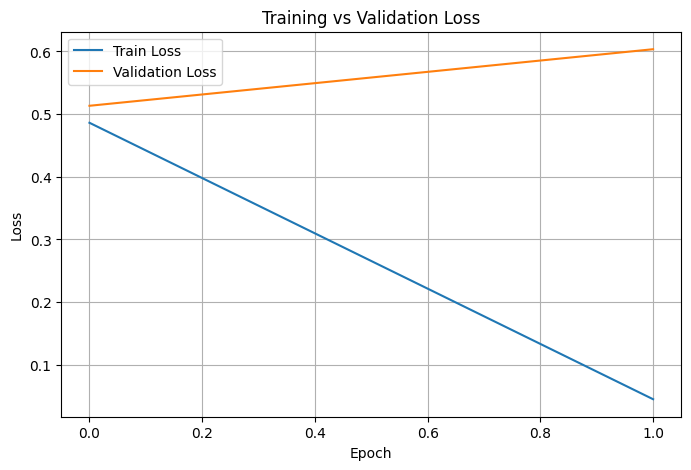

In [10]:
# Plotting the Loss Curve for both Training and Validation phases

plt.figure(figsize=(8, 5))  # Set the figure size

# Plot the training loss history
plt.plot(history[0], label='Train Loss')

# Plot the validation loss history
plt.plot(history[1], label='Validation Loss')

# Add title and axis labels
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

# Add legend to distinguish between train and validation loss
plt.legend()

# Add grid for better readability
plt.grid(True)

# Display the plot
plt.show()

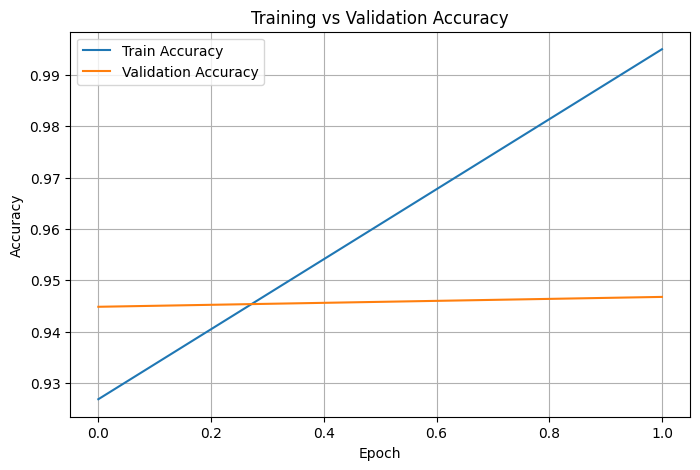

In [11]:
# Plotting the Accuracy Curve for both Training and Validation phases

plt.figure(figsize=(8, 5))  # Set the figure size

# Plot the training accuracy history (moved to CPU for compatibility)
plt.plot([acc.cpu() for acc in history[2]], label='Train Accuracy')

# Plot the validation accuracy history (moved to CPU for compatibility)
plt.plot([acc.cpu() for acc in history[3]], label='Validation Accuracy')

# Add title and axis labels
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

# Add legend to distinguish between train and validation accuracy
plt.legend()

# Add grid for better readability
plt.grid(True)

# Display the plot
plt.show()

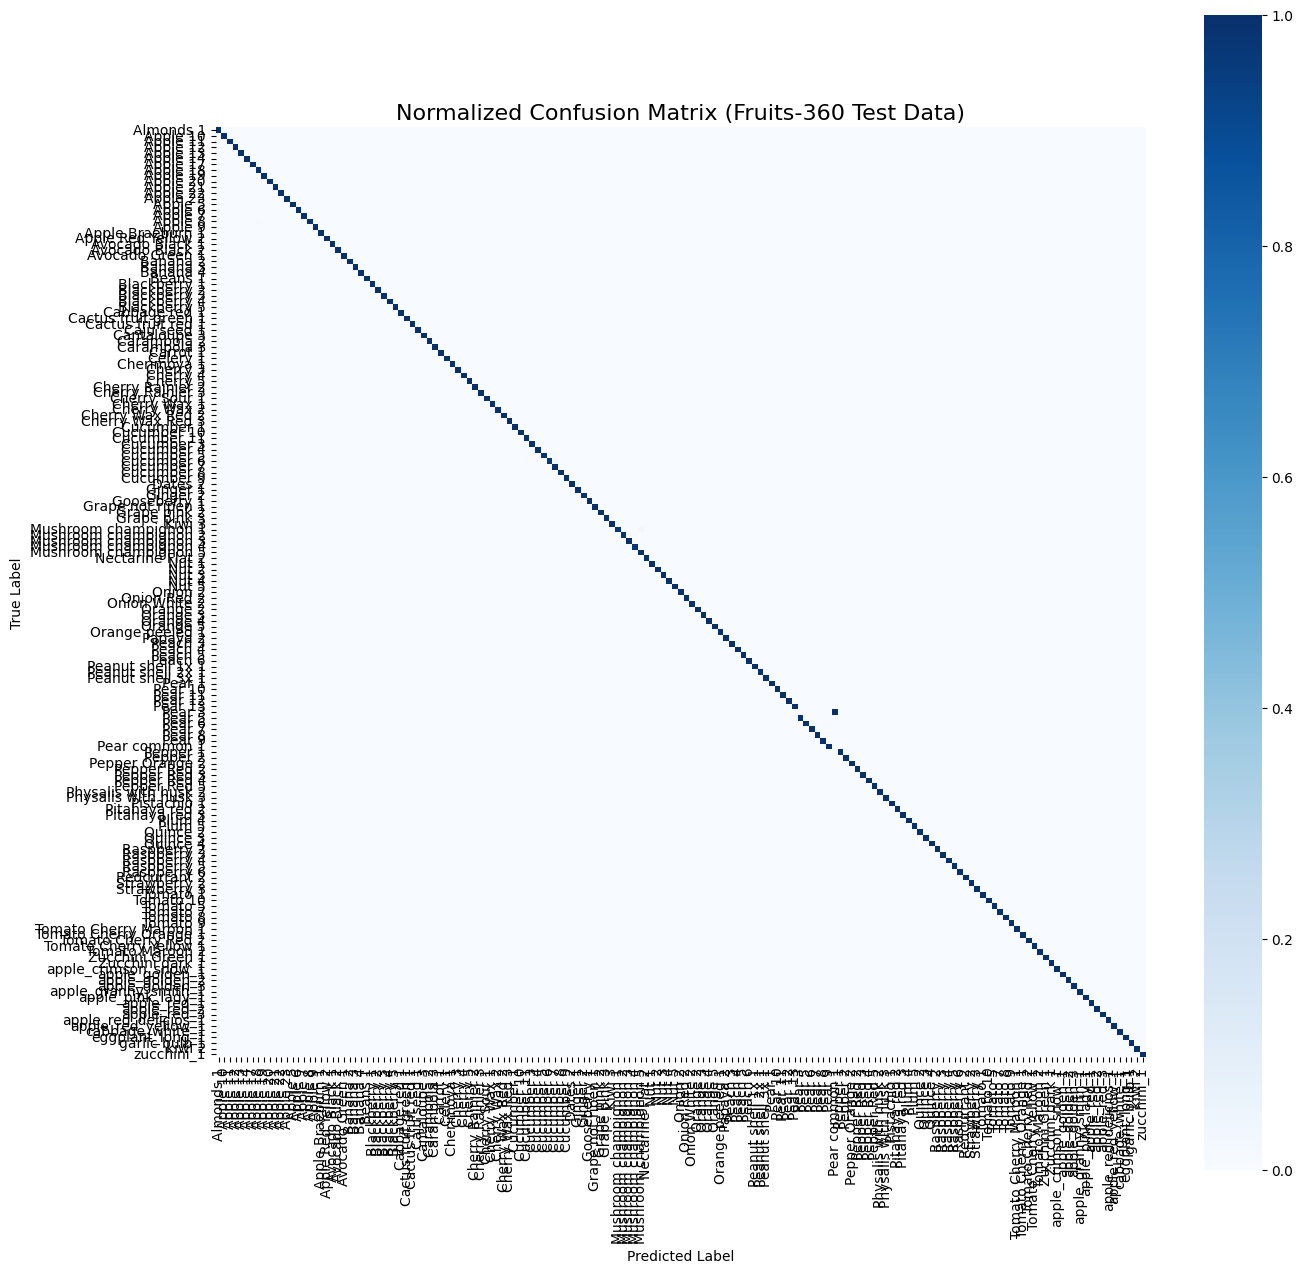

In [12]:
# Generate and plot clean normalized confusion matrix heatmap (without numbers)

# Put model in evaluation mode
model.eval()

# Prepare prediction and label lists
all_labels = []
all_preds = []

# Collect predictions on validation set
with torch.no_grad():
    for inputs, labels in dataloaders['val']:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Compute normalized confusion matrix
cm = confusion_matrix(all_labels, all_preds, normalize='true')

# Plot heatmap only with color, remove annotations for cleaner view
plt.figure(figsize=(15, 15))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar=True, square=True)
plt.title('Normalized Confusion Matrix (Fruits-360 Test Data)', fontsize=16)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [13]:
# Generate a detailed classification report for the test data
# This report includes metrics like precision, recall, f1-score, and support for each class
# 'target_names' provides the class labels for better readability in the report
report = classification_report(all_labels, all_preds, target_names=class_names)

# Print the classification report to the console
print("Classification Report on Fruits-360 Test Data:\n")
print(report)

Classification Report on Fruits-360 Test Data:

                        precision    recall  f1-score   support

             Almonds 1       1.00      1.00      1.00        77
              Apple 10       1.00      1.00      1.00       231
              Apple 11       1.00      1.00      1.00       142
              Apple 12       1.00      1.00      1.00       154
              Apple 13       1.00      1.00      1.00       231
              Apple 14       1.00      1.00      1.00       154
              Apple 17       1.00      1.00      1.00       243
              Apple 18       1.00      1.00      1.00       242
              Apple 19       1.00      1.00      1.00       241
              Apple 20       1.00      1.00      1.00       234
              Apple 21       1.00      1.00      1.00       159
              Apple 22       1.00      1.00      1.00       231
              Apple 23       1.00      1.00      1.00       156
               Apple 5       1.00      1.00      1.00  

In [14]:
# Sample dataset for smoothie recipes

# Define a comprehensive smoothie recipes dictionary
# Each key is a frozenset of ingredient names (including variations and aliases)
# Each value contains recipe details like name, instructions, additional ingredients, and fun facts
# This setup allows flexible matching of predicted labels (including different variations) to recipes
smoothie_recipes = {
    # 1-item smoothies
    frozenset(["banana"]): {
        "name": "Banana Smoothie",
        "instructions": "Blend 1 banana with 1/2 cup of milk.",
        "additional_ingredients": ["milk"],
        "fun_facts": [
            "Bananas are a great source of potassium, which is essential for maintaining healthy heart function.",
            "Bananas contain vitamin B6, which is important for brain health and metabolism."
        ]
    },

    
    frozenset(["apple", "apple_red_yellow_1", "apple_green_1"]): {
        "name": "Apple Smoothie",
        "instructions": "Blend 1 apple with 1/2 cup of almond milk.",
        "additional_ingredients": ["almond milk"],
        "fun_facts": [
            "Apples are high in fiber, which helps regulate digestion and maintain gut health.",
            "Apples contain antioxidants, which may help reduce the risk of chronic diseases."
        ]
    },
 
frozenset(["avocado","avocado black 1","avocado green 1"]): {
    "name": "Avocado Smoothie",
    "instructions": "Blend 1/2 avocado with 1/2 cup of milk.",
    "additional_ingredients": ["milk"],
    "fun_facts": [
        "Avocados are rich in healthy fats, especially monounsaturated fats, which support heart health.",
        "Avocados are a great source of potassium and can help regulate blood pressure."
    ]
},
 
frozenset(["banana"]): {
    "name": "Banana Smoothie",
    "instructions": "Blend 1 banana with 1/2 cup of milk.",
    "additional_ingredients": ["milk"],
    "fun_facts": [
        "Bananas are a great source of potassium, which is essential for maintaining healthy heart function.",
        "Bananas contain vitamin B6, which is important for brain health and metabolism."
    ]
},
 
frozenset(["beans"]): {
    "name": "Beans Smoothie",
    "instructions": "Blend 1/2 cup of cooked beans with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Beans are a great source of plant-based protein, ideal for muscle recovery.",
        "Beans are high in fiber, which aids digestion and helps maintain healthy blood sugar levels."
    ]
},
 
frozenset(["blackberry", "blackberrie 1", "blackberrie 2","blackberrie half rippen 1"]): {
    "name": "Blackberry Smoothie",
    "instructions": "Blend 1/2 cup of blackberries with 1/2 cup of yogurt.",
    "additional_ingredients": ["yogurt"],
    "fun_facts": [
        "Blackberries are rich in vitamin C, which helps boost your immune system.",
        "Blackberries are packed with antioxidants, which help protect your body from free radicals."
    ]
},
 
frozenset(["cabbage red"]): {
    "name": "Red Cabbage Smoothie",
    "instructions": "Blend 1/2 cup of shredded red cabbage with 1/2 cup of apple juice.",
    "additional_ingredients": ["apple juice"],
    "fun_facts": [
        "Red cabbage is high in vitamin C and antioxidants, supporting immune health.",
        "Red cabbage is rich in anthocyanins, which may help protect your heart and reduce inflammation."
    ]
},

frozenset(["cabbage green"]): {
    "name": "Green Cabbage Smoothie",
    "instructions": "Blend 1/2 cup of shredded green cabbage with 1/2 cup of orange juice.",
    "additional_ingredients": ["orange juice"],
    "fun_facts": [
        "Green cabbage is a great source of vitamin K, which is important for bone health.",
        "Cabbage is high in fiber, which supports digestion and helps regulate blood sugar levels."
    ]
},
 
frozenset(["kaju seed"]): {
    "name": "Cashew Seed Smoothie",
    "instructions": "Blend 1/4 cup of cashew seeds with 1/2 cup of coconut milk.",
    "additional_ingredients": ["coconut milk"],
    "fun_facts": [
        "Cashews are a good source of healthy fats, which support heart health.",
        "Cashews are rich in magnesium, which is important for muscle and nerve function."
    ]
},
 
frozenset(["cherimoya"]): {
    "name": "Cherimoya Smoothie",
    "instructions": "Blend 1 cherimoya with 1/2 cup of coconut milk.",
    "additional_ingredients": ["coconut milk"],
    "fun_facts": [
        "Cherimoya is high in vitamin C and antioxidants, which help support your immune system.",
        "Cherimoya is a good source of fiber, which supports healthy digestion."
    ]
},
 
frozenset(["cherry","cherry rainier 3","cherry rainier 2","cherry 3"]): {
    "name": "Cherry Smoothie",
    "instructions": "Blend 1/2 cup of cherries with 1/2 cup of yogurt.",
    "additional_ingredients": ["yogurt"],
    "fun_facts": [
        "Cherries are rich in antioxidants, which may help reduce inflammation and protect against diseases.",
        "Cherries are a natural source of melatonin, which may help improve sleep quality."
    ]
},
 
frozenset(["cucumber"]): {
    "name": "Cucumber Smoothie",
    "instructions": "Blend 1/2 cucumber with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Cucumbers are low in calories and high in water content, making them great for hydration.",
        "Cucumbers contain antioxidants that can help reduce inflammation and improve skin health."
    ]
},
 
frozenset(["gooseberry"]): {
    "name": "Gooseberry Smoothie",
    "instructions": "Blend 1/2 cup of gooseberries with 1/2 cup of yogurt.",
    "additional_ingredients": ["yogurt"],
    "fun_facts": [
        "Gooseberries are rich in vitamin C, which helps support immune health.",
        "Gooseberries have anti-inflammatory properties and can help reduce oxidative stress."
    ]
},
 
frozenset(["pistachio"]): {
    "name": "Pistachio Smoothie",
    "instructions": "Blend 1/4 cup of pistachios with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Pistachios are a great source of protein and healthy fats, which help keep you full longer.",
        "Pistachios contain antioxidants that may help reduce inflammation and protect your heart."
    ]
},
 
frozenset(["quince"]): {
    "name": "Quince Smoothie",
    "instructions": "Blend 1 quince with 1/2 cup of apple juice.",
    "additional_ingredients": ["apple juice"],
    "fun_facts": [
        "Quince is high in vitamin C, which helps boost your immune system.",
        "Quince is known for its anti-inflammatory properties and may help improve digestion."
    ]
},
 
frozenset(["tomato"]): {
    "name": "Tomato Smoothie",
    "instructions": "Blend 1 tomato with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Tomatoes are rich in lycopene, an antioxidant that may help reduce the risk of cancer.",
        "Tomatoes are also a good source of vitamin C and potassium, which are essential for heart health."
    ]
},
 
frozenset(["pear"]): {
    "name": "Pear Smoothie",
    "instructions": "Blend 1 pear with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Pears are high in fiber, which promotes healthy digestion and supports weight loss.",
        "Pears are rich in antioxidants, which help protect the body from free radicals."
    ]
},
 
frozenset(["eggplant"]): {
    "name": "Eggplant Smoothie",
    "instructions": "Blend 1/2 cup of cooked eggplant with 1/2 cup of coconut milk.",
    "additional_ingredients": ["coconut milk"],
    "fun_facts": [
        "Eggplants are high in fiber, which helps promote digestion and support heart health.",
        "Eggplants are rich in antioxidants, which may help protect the body against chronic diseases."
    ]
},
 
frozenset(["zucchini"]): {
    "name": "Zucchini Smoothie",
    "instructions": "Blend 1/2 zucchini with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Zucchini is low in calories and high in water content, making it perfect for hydration.",
        "Zucchini contains antioxidants, which help protect the body from oxidative stress."
    ]
},
    
    
# 2-item smoothies
frozenset(["apple", "banana"]): {
    "name": "Apple Banana Smoothie",
    "instructions": "Blend 1 apple and 1 banana with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Apples and bananas both provide essential vitamins and minerals to boost your immune system.",
        "Bananas add creaminess to the smoothie, while apples contribute a refreshing crisp flavor."
    ]
},
 
frozenset(["apple", "avocado"]): {
    "name": "Apple Avocado Smoothie",
    "instructions": "Blend 1 apple and 1/2 avocado with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Avocados are rich in healthy fats, while apples are high in fiber, making this smoothie perfect for digestion.",
        "This smoothie is both creamy and refreshing, offering a good balance of healthy fats and natural sugars."
    ]
},
 
frozenset(["banana", "blackberry"]): {
    "name": "Banana Blackberry Smoothie",
    "instructions": "Blend 1 banana and 1/2 cup of blackberries with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Blackberries are rich in antioxidants, which help combat oxidative stress and inflammation.",
        "Bananas provide potassium to support muscle function, and blackberries add a tangy flavor to this smoothie."
    ]
},
 
frozenset(["beans", "avocado"]): {
    "name": "Beans Avocado Smoothie",
    "instructions": "Blend 1/2 cup of cooked beans and 1/2 avocado with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Beans provide plant-based protein and fiber, while avocado adds healthy fats to make the smoothie creamy.",
        "This smoothie is perfect for a protein-packed snack or breakfast."
    ]
},
 
frozenset(["cabbage red", "cherry"]): {
    "name": "Red Cabbage Cherry Smoothie",
    "instructions": "Blend 1/2 cup of shredded red cabbage and 1/2 cup of cherries with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Red cabbage contains antioxidants, while cherries provide natural sweetness and anti-inflammatory properties.",
        "Together, they create a vibrant and health-boosting smoothie."
    ]
},
 
frozenset(["blackberry", "gooseberry"]): {
    "name": "Blackberry Gooseberry Smoothie",
    "instructions": "Blend 1/2 cup of blackberries and 1/2 cup of gooseberries with 1/2 cup of yogurt.",
    "additional_ingredients": ["yogurt"],
    "fun_facts": [
        "Blackberries and gooseberries are both high in vitamin C, which supports the immune system.",
        "These berries are packed with antioxidants that help protect the body from free radicals."
    ]
},
 
frozenset(["pistachio", "quince"]): {
    "name": "Pistachio Quince Smoothie",
    "instructions": "Blend 1/4 cup of pistachios and 1 quince with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Pistachios add a nutty flavor and healthy fats to this smoothie, while quince adds a unique, tart sweetness.",
        "This combination is both delicious and loaded with nutrients like fiber, vitamins, and minerals."
    ]
},
 
frozenset(["tomato", "cucumber"]): {
    "name": "Tomato Cucumber Smoothie",
    "instructions": "Blend 1 tomato and 1/2 cucumber with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Tomatoes are rich in lycopene, which is great for heart health, while cucumbers add a refreshing and hydrating touch.",
        "This smoothie is perfect for staying hydrated and getting essential vitamins."
    ]
},
 
frozenset(["eggplant", "zucchini"]): {
    "name": "Eggplant Zucchini Smoothie",
    "instructions": "Blend 1/2 cup of cooked eggplant and 1/2 zucchini with 1/2 cup of coconut milk.",
    "additional_ingredients": ["coconut milk"],
    "fun_facts": [
        "Eggplants are high in fiber, which helps digestion, while zucchini is low in calories and great for hydration.",
        "This smoothie is a nutrient-packed blend of antioxidants and vitamins, supporting overall health."
    ]
},
 
frozenset(["pear", "cherry"]): {
    "name": "Pear Cherry Smoothie",
    "instructions": "Blend 1 pear and 1/2 cup of cherries with 1/2 cup of yogurt.",
    "additional_ingredients": ["yogurt"],
    "fun_facts": [
        "Pears provide fiber for healthy digestion, while cherries add antioxidants and help reduce inflammation.",
        "This smoothie is both sweet and tangy, with a creamy texture from the yogurt."
    ]
},

# 3-item smoothies
frozenset(["apple", "banana", "blackberry"]): {
    "name": "Apple Banana Blackberry Smoothie",
    "instructions": "Blend 1 apple, 1 banana, and 1/2 cup of blackberries with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Blackberries are rich in antioxidants, while apples and bananas provide fiber and natural sweetness.",
        "This smoothie is a great combination of energy-boosting and immune-boosting ingredients."
    ]
},
 
frozenset(["avocado", "cabbage red", "tomato"]): {
    "name": "Avocado Cabbage Red Tomato Smoothie",
    "instructions": "Blend 1/2 avocado, 1/2 cup of shredded red cabbage, and 1 tomato with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Avocados are loaded with healthy fats, while red cabbage and tomatoes offer a great source of vitamins and antioxidants.",
        "This smoothie is an immune-boosting powerhouse, providing anti-inflammatory properties and heart-healthy fats."
    ]
},
 
frozenset(["banana", "beans", "gooseberry"]): {
    "name": "Banana Beans Gooseberry Smoothie",
    "instructions": "Blend 1 banana, 1/2 cup of cooked beans, and 1/2 cup of gooseberries with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Bananas provide potassium for muscle function, while beans add plant-based protein and gooseberries offer vitamin C.",
        "This smoothie is perfect for energy and muscle recovery after a workout."
    ]
},
 
frozenset(["blackberry", "cherrimuya", "pistachio"]): {
    "name": "Blackberry Cherrimuya Pistachio Smoothie",
    "instructions": "Blend 1/2 cup of blackberries, 1/2 cup of cherrimuya, and 1/4 cup of pistachios with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Blackberries and cherrimuya are loaded with antioxidants, while pistachios provide healthy fats and protein.",
        "This smoothie is perfect for a nutritious snack that keeps you full and energized."
    ]
},
 
frozenset(["cabbage green", "gooseberry", "pear"]): {
    "name": "Green Cabbage Gooseberry Pear Smoothie",
    "instructions": "Blend 1/2 cup of shredded green cabbage, 1/2 cup of gooseberries, and 1 pear with 1/2 cup of yogurt.",
    "additional_ingredients": ["yogurt"],
    "fun_facts": [
        "Green cabbage is rich in vitamin K, while gooseberries and pears provide essential fiber and vitamin C.",
        "This smoothie is a great way to support your immune system and promote healthy digestion."
    ]
},
 
frozenset(["avocado", "pistachio", "tomato"]): {
    "name": "Avocado Pistachio Tomato Smoothie",
    "instructions": "Blend 1/2 avocado, 1/4 cup of pistachios, and 1 tomato with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Avocados add healthy fats, pistachios provide protein, and tomatoes are a great source of lycopene.",
        "This smoothie is packed with nutrients that support heart health and reduce inflammation."
    ]
},
 
frozenset(["cherry", "eggplant", "zucchini"]): {
    "name": "Cherry Eggplant Zucchini Smoothie",
    "instructions": "Blend 1/2 cup of cherries, 1/2 cup of cooked eggplant, and 1/2 zucchini with 1/2 cup of coconut milk.",
    "additional_ingredients": ["coconut milk"],
    "fun_facts": [
        "Cherries provide antioxidants, while eggplant and zucchini offer vitamins and fiber.",
        "This smoothie is a great option for those looking to detox and boost their digestive health."
    ]
},
 
frozenset(["avocado", "banana", "pistachio"]): {
    "name": "Avocado Banana Pistachio Smoothie",
    "instructions": "Blend 1/2 avocado, 1 banana, and 1/4 cup of pistachios with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Avocados are full of healthy fats, while pistachios provide protein and bananas give you natural energy.",
        "This smoothie is great for promoting healthy skin and maintaining energy levels throughout the day."
    ]
},
 
frozenset(["beans", "tomato", "cabbage green"]): {
    "name": "Beans Tomato Green Cabbage Smoothie",
    "instructions": "Blend 1/2 cup of cooked beans, 1 tomato, and 1/2 cup of shredded green cabbage with 1/2 cup of vegetable broth.",
    "additional_ingredients": ["vegetable broth"],
    "fun_facts": [
        "Beans are rich in protein, tomatoes are a great source of antioxidants, and cabbage is packed with fiber.",
        "This smoothie is a nutritious and hearty option to keep you full and energized."
    ]
},
 
frozenset(["blackberry", "quince", "zucchini"]): {
    "name": "Blackberry Quince Zucchini Smoothie",
    "instructions": "Blend 1/2 cup of blackberries, 1 quince, and 1/2 zucchini with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Blackberries and quince are both rich in antioxidants, while zucchini adds vitamins and minerals.",
        "This smoothie is a flavorful and refreshing option, perfect for hot summer days."
    ]
},

    # 4-item smoothies
frozenset(["banana", "avocado", "pear", "blackberry"]): {
    "name": "Banana Avocado Pear Blackberry Smoothie",
    "instructions": "Blend 1 banana, 1/2 avocado, 1 pear, and 1/2 cup of blackberries with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Bananas provide energy, while avocados offer healthy fats, pears provide fiber, and blackberries are full of antioxidants.",
        "This smoothie is great for a balanced meal with healthy fats, fiber, and a burst of antioxidants."
    ]
},
 
frozenset(["apple", "tomato", "pistachio", "cabbage red"]): {
    "name": "Apple Tomato Pistachio Cabbage Red Smoothie",
    "instructions": "Blend 1 apple, 1 tomato, 1/4 cup of pistachios, and 1/2 cup of shredded red cabbage with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Tomatoes and cabbage are loaded with antioxidants, while apples and pistachios provide fiber and healthy fats.",
        "This smoothie is packed with nutrients that promote heart health and support your immune system."
    ]
},
 
frozenset(["gooseberry", "avocado", "banana", "quince"]): {
    "name": "Gooseberry Avocado Banana Quince Smoothie",
    "instructions": "Blend 1/2 cup of gooseberries, 1/2 avocado, 1 banana, and 1 quince with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Gooseberries are rich in vitamin C, while avocado provides healthy fats, bananas offer potassium, and quince adds a fragrant sweetness.",
        "This smoothie is an immunity-boosting powerhouse, promoting skin health and energy."
    ]
},
 
frozenset(["cabbage green", "tomato", "pistachio", "eggplant"]): {
    "name": "Cabbage Green Tomato Pistachio Eggplant Smoothie",
    "instructions": "Blend 1/2 cup of shredded green cabbage, 1 tomato, 1/4 cup of pistachios, and 1/2 cup of cooked eggplant with 1/2 cup of vegetable broth.",
    "additional_ingredients": ["vegetable broth"],
    "fun_facts": [
        "Cabbage and eggplant are high in fiber, while pistachios add protein and tomatoes are a great source of lycopene.",
        "This smoothie is perfect for detoxing, supporting digestion, and boosting your immune system."
    ]
},
 
frozenset(["blackberry", "cherrimuya", "avocado", "zucchini"]): {
    "name": "Blackberry Cherrimuya Avocado Zucchini Smoothie",
    "instructions": "Blend 1/2 cup of blackberries, 1/2 cup of cherrimuya, 1/2 avocado, and 1/2 zucchini with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Blackberries and cherrimuya are rich in antioxidants, while avocado provides healthy fats and zucchini adds essential vitamins.",
        "This smoothie is a nutrient-packed treat that supports healthy skin, digestion, and overall well-being."
    ]
},
 
frozenset(["banana", "blackberry", "beans", "pistachio"]): {
    "name": "Banana Blackberry Beans Pistachio Smoothie",
    "instructions": "Blend 1 banana, 1/2 cup of blackberries, 1/2 cup of cooked beans, and 1/4 cup of pistachios with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Bananas and blackberries provide fiber and antioxidants, while beans add protein and pistachios offer healthy fats.",
        "This smoothie is great for energy, muscle recovery, and immune support."
    ]
},
 
frozenset(["tomato", "quince", "cabbage red", "gooseberry"]): {
    "name": "Tomato Quince Cabbage Red Gooseberry Smoothie",
    "instructions": "Blend 1 tomato, 1 quince, 1/2 cup of shredded red cabbage, and 1/2 cup of gooseberries with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Tomatoes and cabbage are high in antioxidants, quince provides a sweet flavor, and gooseberries offer a healthy dose of vitamin C.",
        "This smoothie is a fantastic immune booster, rich in antioxidants and vitamins."
    ]
},
 
frozenset(["avocado", "zucchini", "pistachio", "cherry"]): {
    "name": "Avocado Zucchini Pistachio Cherry Smoothie",
    "instructions": "Blend 1/2 avocado, 1/2 zucchini, 1/4 cup of pistachios, and 1/2 cup of cherries with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Avocado provides healthy fats, zucchini adds vitamins, pistachios provide protein, and cherries are loaded with antioxidants.",
        "This smoothie is perfect for maintaining energy, skin health, and reducing inflammation."
    ]
},
 
frozenset(["pear", "eggplant", "zucchini", "blackberry"]): {
    "name": "Pear Eggplant Zucchini Blackberry Smoothie",
    "instructions": "Blend 1 pear, 1/2 cup of cooked eggplant, 1/2 zucchini, and 1/2 cup of blackberries with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Pear provides fiber, eggplant offers antioxidants, zucchini is rich in vitamins, and blackberries are packed with nutrients.",
        "This smoothie is a refreshing way to support digestion and maintain skin health."
    ]
},

    # 5-item smoothies
frozenset(["banana", "avocado", "tomato", "pistachio", "pear"]): {
    "name": "Banana Avocado Tomato Pistachio Pear Smoothie",
    "instructions": "Blend 1 banana, 1/2 avocado, 1 tomato, 1/4 cup of pistachios, and 1 pear with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Bananas provide energy, avocados offer healthy fats, tomatoes are packed with antioxidants, pistachios provide protein, and pears add fiber.",
        "This smoothie is an excellent source of vitamins and minerals to support energy, digestion, and immune health."
    ]
},

    frozenset(["blackberry", "avocado", "gooseberry", "quince", "cabbage green"]): {
    "name": "Blackberry Avocado Gooseberry Quince Cabbage Green Smoothie",
    "instructions": "Blend 1/2 cup of blackberries, 1/2 avocado, 1/2 cup of gooseberries, 1 quince, and 1/2 cup of shredded green cabbage with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Blackberries and gooseberries are rich in antioxidants, avocado provides healthy fats, quince adds a fragrant flavor, and cabbage is great for digestion.",
        "This smoothie is packed with vitamins, fiber, and antioxidants to promote healthy skin and a strong immune system."
    ]
},
 
frozenset(["tomato", "blackberry", "avocado", "cabbage red", "cherry"]): {
    "name": "Tomato Blackberry Avocado Cabbage Red Cherry Smoothie",
    "instructions": "Blend 1 tomato, 1/2 cup of blackberries, 1/2 avocado, 1/2 cup of shredded red cabbage, and 1/2 cup of cherries with 1/2 cup of vegetable broth.",
    "additional_ingredients": ["vegetable broth"],
    "fun_facts": [
        "Tomatoes and cherries are rich in antioxidants, avocado provides healthy fats, cabbage supports digestion, and blackberries are loaded with vitamins.",
        "This smoothie is perfect for boosting your immune system and promoting healthy digestion."
    ]
},
 
frozenset(["banana", "gooseberry", "beans", "pistachio", "pear"]): {
    "name": "Banana Gooseberry Beans Pistachio Pear Smoothie",
    "instructions": "Blend 1 banana, 1/2 cup of gooseberries, 1/2 cup of cooked beans, 1/4 cup of pistachios, and 1 pear with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Bananas are high in potassium, gooseberries offer vitamin C, beans add protein, pistachios provide healthy fats, and pears add fiber.",
        "This smoothie is a great option for muscle recovery and boosting your immune system."
    ]
},
 
frozenset(["avocado", "tomato", "zucchini", "eggplant", "pistachio"]): {
    "name": "Avocado Tomato Zucchini Eggplant Pistachio Smoothie",
    "instructions": "Blend 1/2 avocado, 1 tomato, 1/2 zucchini, 1/2 cup of cooked eggplant, and 1/4 cup of pistachios with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Avocado provides healthy fats, tomatoes are packed with antioxidants, zucchini adds vitamins, eggplant is rich in fiber, and pistachios offer protein.",
        "This smoothie supports digestion, heart health, and offers a balanced intake of nutrients."
    ]
},
 
# 5+ Item smoothies
frozenset(["banana", "avocado", "blackberry", "tomato", "pear", "quince"]): {
    "name": "Banana Avocado Blackberry Tomato Pear Quince Smoothie",
    "instructions": "Blend 1 banana, 1/2 avocado, 1/2 cup of blackberries, 1 tomato, 1 pear, and 1 quince with 1/2 cup of almond milk.",
    "additional_ingredients": ["almond milk"],
    "fun_facts": [
        "Bananas and avocados are energy-boosting, blackberries and tomatoes are rich in antioxidants, pears add fiber, and quince offers a fragrant sweetness.",
        "This smoothie is an antioxidant-packed powerhouse, great for boosting your energy and immune system."
    ]
},
 
frozenset(["cabbage green", "blackberry", "zucchini", "pistachio", "tomato", "gooseberry"]): {
    "name": "Cabbage Green Blackberry Zucchini Pistachio Tomato Gooseberry Smoothie",
    "instructions": "Blend 1/2 cup of shredded green cabbage, 1/2 cup of blackberries, 1/2 zucchini, 1/4 cup of pistachios, 1 tomato, and 1/2 cup of gooseberries with 1/2 cup of vegetable broth.",
    "additional_ingredients": ["vegetable broth"],
    "fun_facts": [
        "Cabbage, zucchini, and tomatoes are full of fiber and antioxidants, while blackberries and gooseberries offer a burst of vitamin C and pistachios provide healthy fats.",
        "This smoothie is ideal for digestion, reducing inflammation, and supporting your immune system."
    ]
},
 
frozenset(["banana", "cherrimuya", "avocado", "blackberry", "pistachio", "eggplant"]): {
    "name": "Banana Cherrimuya Avocado Blackberry Pistachio Eggplant Smoothie",
    "instructions": "Blend 1 banana, 1/2 cup of cherrimuya, 1/2 avocado, 1/2 cup of blackberries, 1/4 cup of pistachios, and 1/2 cup of cooked eggplant with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Bananas and avocados offer energy and healthy fats, cherrimuya and blackberries provide antioxidants, pistachios add protein, and eggplant promotes heart health.",
        "This smoothie is an amazing blend of antioxidants and healthy fats to fuel your body and promote well-being."
    ]
},
 
frozenset(["tomato", "avocado", "eggplant", "zucchini", "blackberry", "cabbage red"]): {
    "name": "Tomato Avocado Eggplant Zucchini Blackberry Cabbage Red Smoothie",
    "instructions": "Blend 1 tomato, 1/2 avocado, 1/2 cup of cooked eggplant, 1/2 zucchini, 1/2 cup of blackberries, and 1/2 cup of shredded red cabbage with 1/2 cup of vegetable juice.",
    "additional_ingredients": ["vegetable juice"],
    "fun_facts": [
        "Tomatoes and eggplants are high in antioxidants, avocado provides healthy fats, zucchini and cabbage offer essential vitamins, and blackberries are loaded with nutrients.",
        "This smoothie is great for promoting heart health, reducing inflammation, and supporting overall health."
    ]
},
 
frozenset(["banana", "quince", "gooseberry", "pistachio", "avocado", "zucchini"]): {
    "name": "Banana Quince Gooseberry Pistachio Avocado Zucchini Smoothie",
    "instructions": "Blend 1 banana, 1 quince, 1/2 cup of gooseberries, 1/4 cup of pistachios, 1/2 avocado, and 1/2 zucchini with 1/2 cup of coconut water.",
    "additional_ingredients": ["coconut water"],
    "fun_facts": [
        "Bananas, quince, and gooseberries are high in vitamins, avocado provides healthy fats, pistachios offer protein, and zucchini is a great source of fiber.",
        "This smoothie is a nutrient-dense treat, providing hydration, antioxidants, and a balanced source of energy."
    ]
}
    
}

Using my photos from: /kaggle/input/datasets/laharisingaraju19/my-fruits

Recipe for apple_red_yellow_1: Apple Smoothie
Instructions: Blend 1 apple with 1/2 cup of almond milk.
Additional Ingredients: almond milk
Fun Facts:
  - Apples are high in fiber, which helps regulate digestion and maintain gut health.
  - Apples contain antioxidants, which may help reduce the risk of chronic diseases.
No recipe found for Cucumber 7
No recipe found for Blackberry 4
No recipe found for Pepper Orange 2


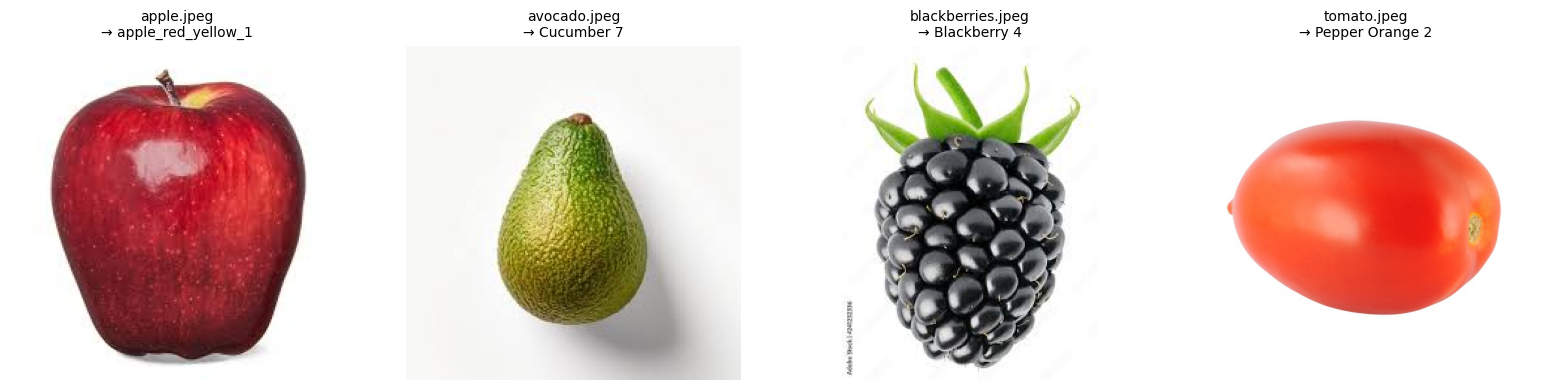

In [15]:
# --------------------------------------------------
# Predict images, display results, and map to recipes for some random imgs
# --------------------------------------------------

# Define a function to predict label from image using the trained model
def predict_custom_image(image_path, model):
    img = Image.open(image_path).convert('RGB')

    # Apply validation transforms
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])

    img_tensor = transform(img).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        outputs = model(img_tensor)
        _, predicted = torch.max(outputs, 1)
        predicted_class = class_names[predicted.item()]

    return predicted_class, img

# Set the folder containing uploaded images
custom_folder = glob.glob('/kaggle/input/**/my-fruits', recursive=True)[0]
print("Using my photos from:", custom_folder)
custom_images = os.listdir(custom_folder)

# Set figure size for displaying images
plt.figure(figsize=(16, 4))

# Loop through each uploaded image
for idx, img_name in enumerate(custom_images):
    try:
        # Predict label from image
        img_path = os.path.join(custom_folder, img_name)
        pred_label, img = predict_custom_image(img_path, model)

        # Display the image and prediction
        plt.subplot(1, len(custom_images), idx+1)
        plt.imshow(img)
        plt.title(f"{img_name}\n→ {pred_label}", fontsize=10)
        plt.axis('off')

        # Attempt to match label inside any recipe key using 'in'
        found_recipe = False
        for key in smoothie_recipes:
            if any(pred_label.lower() in item.lower() for item in key):
                recipe = smoothie_recipes[key]
                print(f"\nRecipe for {pred_label}: {recipe['name']}")
                print(f"Instructions: {recipe['instructions']}")
                print(f"Additional Ingredients: {', '.join(recipe['additional_ingredients'])}")
                print(f"Fun Facts:")
                for fact in recipe['fun_facts']:
                    print(f"  - {fact}")
                found_recipe = True
                break

        if not found_recipe:
            print(f"No recipe found for {pred_label}")

    except Exception as e:
        print(f"Error processing {img_name}: {e}")

# Show all the images and predictions
plt.tight_layout()
plt.show()
# --------------------------------------------------